* Discente: Brener Gomes dos Santos
* Data: 30/01/2026

# Setup

In [1]:
import gdown
import cv2

import numpy as np
import matplotlib.pyplot as plt

from skimage import data, color, img_as_float
from skimage.util import img_as_ubyte
from skimage import data
from skimage.morphology import disk
from skimage.filters import median

from skimage.filters import prewitt_h, prewitt_v, sobel_h, sobel_v, roberts

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from skimage.filters import threshold_otsu

from skimage.morphology import (
    footprint_rectangle,
    diamond,
    disk,
    octahedron,
    ball,
    octagon,
    star,
)

from skimage.morphology import binary_erosion


# Seleção da imagem do **Dataset**

* Gabarito das imagens que compõe o dataset



```
ID                                  Nome
1PB64M-pLASGEqTdAo_MwDMV-r6anWMjP - caneca-1.jpeg
1jz1PsQNkF1HsBxaAgsMExpNSvNTh2pfv - caneca-2.jpeg
1rj4m7_6bYOWlTuesCDKc-zxkxnvQMxbi - caneca-3.jpeg
1Lb-gRa4ji1xIKIWF_KFF-_dOwmmlO70C - controle-1.jpeg
1yCyoMkgw8hEiVa2FF3nmLAtMDyRifndu - controle-2.jpeg
1l0LcAytHayglu23RZs4KjVTwaJE_gcly - controle-3.jpeg
15IoNG9z81iDLPW63oFW-PG6FIX1TC3Q- - isqueiro-1.jpeg
1BEdhnhscAUrTdO_lHf7wrg6CBnPCa0pA - isqueiro-2.jpeg
1z64LToeGXvmzVuIHexTizjyRog5Du3t4 - isqueiro-3.jpeg
1oNwhAVSsb6Pq8M9j2zVKHiBH1iJui5cB - mouse-1.jpeg
17U3UDwnZ9dP8r5MIsyE2ujXJ2H3nXIrJ - mouse-2.jpeg
1C-llHgcGvNXgzXa2v6jtZaIebxvqCT-g - mouse-3.jpeg

https://drive.google.com/drive/folders/1Qe_e2pp-Sbzc2WmwR1RbCk4o6SBKv0EA?usp=sharing
```



* Seleção da da imagem conforme a escolhida no gabarito

In [2]:
# Carrega uma imagem do dataset pela ID e nomeia ela na pasta.
def dataset(id="1BEdhnhscAUrTdO_lHf7wrg6CBnPCa0pA", name="isqueiro-2.jpeg"):
  url = f'https://drive.google.com/uc?id={id}'

  try:
    gdown.download(url, name, quiet=False) # Faz o download da imagem
    img = cv2.imread(name)                 # Lê a imagem e armazena em var
    img = np.array(img)                    # Converte em array numpy
    img = color.rgb2gray(img)              # Coloca em escala de cinza
    return img
  except Exception as e:
    print(f"Erro ao baixar ou processar a imagem: {e}")
    print("Retornando imagem padrão (camera) da skimage.")
    return img_as_float(data.camera())     # Retorna data.camera() se except

In [3]:
image = dataset()

Downloading...
From: https://drive.google.com/uc?id=1BEdhnhscAUrTdO_lHf7wrg6CBnPCa0pA
To: /content/isqueiro-2.jpeg
100%|██████████| 150k/150k [00:00<00:00, 33.2MB/s]


* Visualização de imagens

In [4]:
def mostra_compara(img1, img2,  t1='img1', t2='img2'):
    # --- Visualização ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes.ravel()

    ax[0].imshow(img1, cmap="gray")
    ax[0].set_title(t1)

    ax[1].imshow(img2, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title(t2)

    for a in ax:
        a.axis("off")

    fig.tight_layout()
    plt.show()

# Pré-processamento: Redução de ruído e suavização


* Filtro de **Mediana**

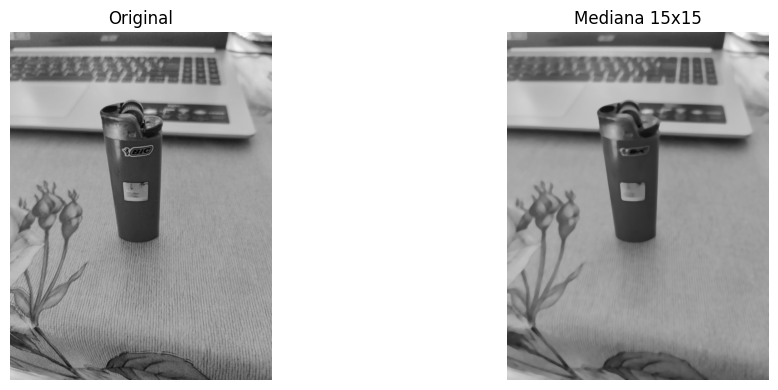

In [5]:
K15x15 = np.ones((15, 15), dtype=np.float64)

def medianImage(img, kernel):
    """Filtro da mediana de uma imagem em nivel de cinza."""
    res = median(img, kernel)
    return res

# Aplicação de filtro Mediana
resMedian15x15 = medianImage(image, K15x15)

mostra_compara(image, resMedian15x15, 'Original', 'Mediana 15x15')

# Realce de Atributos e Detecção de Bordas

* Prewitt (realce de bordas)

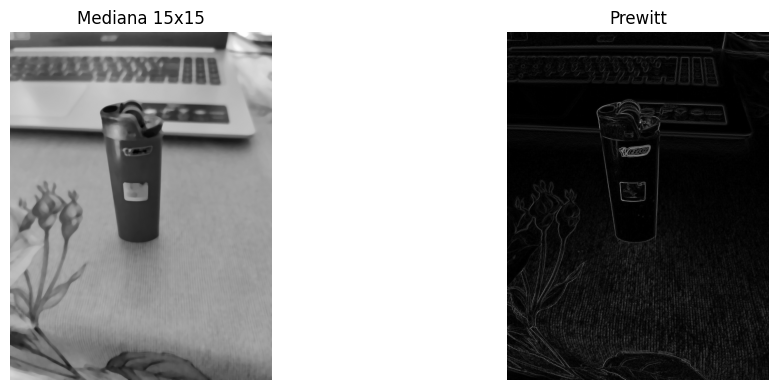

In [6]:
def normalize01(x):
    x = x.astype(np.float64)
    x = x - x.min()
    if x.max() > 0:
        x = x / x.max()
    return x

def grad_magnitude(gx, gy):
    return np.sqrt(gx**2 + gy**2)

gx = prewitt_h(image)
gy = prewitt_v(image)
mag = grad_magnitude(gx, gy)

normal_mag = normalize01(mag)

mostra_compara(resMedian15x15, normal_mag, 'Mediana 15x15', 'Prewitt')

# Segmentação (Limiarização)

* Aplicação de Limiar (Thresholding)

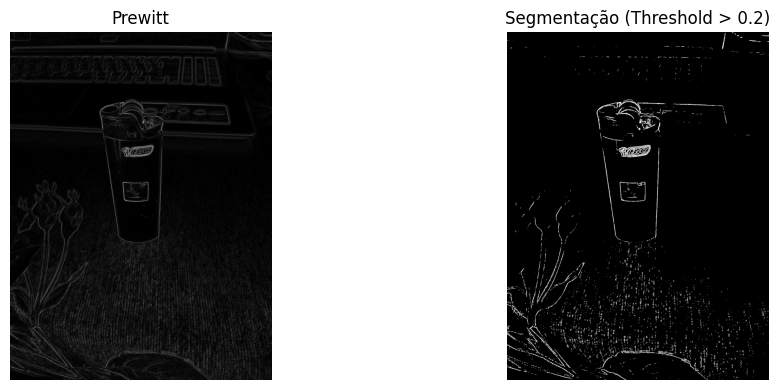

In [7]:
threshold_value = 0.2
binary_segmentation = normal_mag > threshold_value

mostra_compara(normal_mag, binary_segmentation, 'Prewitt', f'Segmentação (Threshold > {threshold_value})')

* Erosão a partir de um objeto estruturante

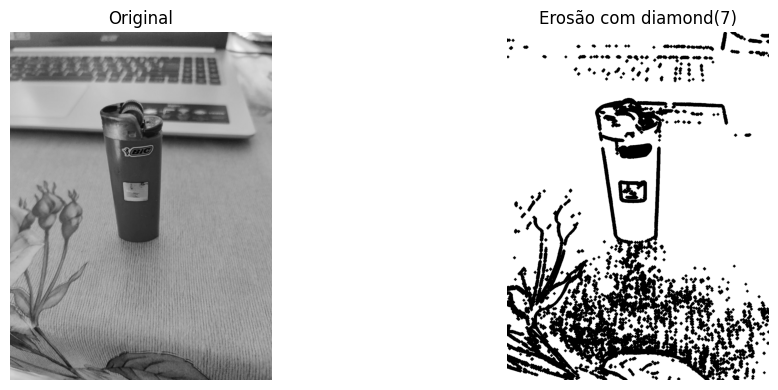

In [8]:
# Generate 2D structuring elements.
struc_2d = {
    "square 15x15": footprint_rectangle((15, 15)),
    "rectangle 15x10": footprint_rectangle((15, 10)),
    "diamond(7)": diamond(7),
    "disk(7)": disk(7),
    "octagon(7, 4)": octagon(7, 4),
    "star(5)": star(5),
}

# Aplicando a erosão com a estrutura Star(5)
eroded_image = binary_erosion(~binary_segmentation, struc_2d["diamond(7)"])

mostra_compara(image, eroded_image, 'Original', 'Erosão com diamond(7)')